# Experiment run — Kraus tomography "unpack" (không dùng class)

Học một unitary Haar-random $\mathcal{E}$ bằng các toán tử Kraus $\{K_i\}$ sao cho
$\mathcal{E}^\dagger\, K(\rho)\, \mathcal{E} \approx \rho$ với mọi probe state $\rho$, trong đó
$K(\rho) = \sum_i K_i \rho K_i^\dagger$. Kết quả tương ứng **Fig. 2** và **Fig. 3** trong paper.

Toàn bộ những gì `KrausTomography` làm được viết thẳng ra bằng **hàm thuần** của `qtomo_skeleton`
(generator, linalg, quantum_ops, metric, gradient, optimizer) — không có class `Tomography` nào.
Mục tiêu: hiểu luồng, rồi **copy từng khối** vào `src/qtomo_skeleton/tomography.py`.

| Khối | Nội dung | Trở thành |
|---|---|---|
| `[B1]` | kiểm tra input, seed → RNG của model | `__init__` (đã viết sẵn) |
| `[B2]` | tập trạng thái train | `__init__` (đã viết sẵn) |
| `[B3]` | Kraus khởi tạo | `__init__` (đã viết sẵn) |
| `[B4]` | process đích + `data_process_fn` | **ngoài class**: người dùng truyền vào `fit` |
| `[B5]` | hàm loss theo tham số | `fit` — TODO 3 |
| `[B6]` | vòng lặp tối ưu | `fit` — TODO 3 |
| `[B7]` | kết quả train | `fit` — TODO 3 (và `is_fitted` — TODO 1) |
| `[B8]` | đánh giá trên trạng thái mới | `evaluate` — TODO 4 |
| `[B9]` | đóng gói + lưu `.npz` | `TomographyResult.from_model(...)` khi đã có class |

**Cấu trúc:** Phần 1 — một run, mỗi khối một ô · Phần 2 — ghép các khối thành một *hàm* và lặp nhiều
run / số qubit · Phần 3 — đọc lại từ đĩa và vẽ Fig. 2, Fig. 3.

Chạy từ thư mục `workshop/`: *Kernel → Restart & Run All*.

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # ẩn log khởi động của TensorFlow

# Dùng qtomo_skeleton trong workshop/src. Đã `pip install -e .` thì có thể xoá 3 dòng dưới.
SRC = (Path.cwd() / "src").resolve()
if SRC.is_dir() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

%matplotlib inline
import numpy as np
import tensorflow as tf

import qtomo_skeleton
from qtomo_skeleton import generator, gradient, linalg, metric, plot, quantum_ops, writer
from qtomo_skeleton.optimizer import AdamOptimizer
from qtomo_skeleton.writer import Evaluation, TomographyResult

print("qtomo_skeleton", qtomo_skeleton.__version__, "từ", Path(qtomo_skeleton.__file__).parent)

qtomo_skeleton 0.2.0 từ D:\Research\workshop\src\qtomo_skeleton


## Cấu hình
`NUM_QUBITS`, `SEED` dùng cho Phần 1 (một run). `QUBITS`, `RUNS` dùng cho Phần 2 (quét).
Tăng `RUNS`, `EPOCHS`, `NUM_RHO` để gần với paper hơn (chạy lâu hơn).

> Với cấu hình nhỏ mặc định, 1 qubit hội tụ tới infidelity ~1e-8, còn 2 qubit thường dừng ở 0.05–0.9:
> 3 probe state chưa đủ ràng buộc một unitary 4×4 và việc train hay kẹt ở cực tiểu địa phương.
> Đó là đặc tính của thuật toán, không phải lỗi của notebook.

In [2]:
# Phần 1 — một run
NUM_QUBITS = 1
SEED = 100

# Phần 2 — quét
QUBITS = [1, 2]       # số qubit cần quét
RUNS = 3              # số run (seed khác nhau) cho mỗi số qubit

# Chung
NUM_RHO = 3           # số probe state để train
NUM_KRAUS = 1         # số toán tử Kraus
NUM_TEST = 5          # số trạng thái test
EPOCHS = 300
LR = 0.05
LOG_EVERY = 50        # in loss mỗi LOG_EVERY epoch (Phần 1)

OUTPUT_DIR = Path("output") / "experiment_run"
FIGURE_DIR = OUTPUT_DIR / "figures"

---
# Phần 1 — Một run, từng khối một

## [B1] seed → RNG của model  ·  → `KrausTomography.__init__`
Kiểm tra input bằng `ValueError` (thư viện không dùng `assert`). **Một** `Generator` cho mọi thứ ngẫu nhiên
của model, dùng theo thứ tự [B2] rồi [B3] — đổi thứ tự thì cùng seed ra kết quả khác.

In [3]:
if NUM_QUBITS < 1:
    raise ValueError(f"num_qubits must be >= 1, got {NUM_QUBITS}.")
model_rng = np.random.default_rng(SEED)
dim = 2**NUM_QUBITS

## [B2] Tập trạng thái train $\rho_i$  ·  → `KrausTomography.__init__`
Trạng thái Haar ngẫu nhiên (mặc định `6**num_qubits` trạng thái nếu `num_rho=None`). Trong class, người dùng
còn có thể truyền `training_states=` (đã viết sẵn trong `_build_training_set`).

⚠ Đừng train bằng trạng thái thuần *chính xác* như $|0\rangle\langle 0|$: gradient của `sqrtm` trong fidelity suy biến.

In [4]:
target_rho_set = generator.haar_probe_states(NUM_QUBITS, NUM_RHO, model_rng)
print(len(target_rho_set), "trạng thái train, shape", target_rho_set[0].shape)

3 trạng thái train, shape (2, 2)


## [B3] Kraus khởi tạo  ·  → `KrausTomography.__init__`
Đã chuẩn hoá để $\sum_i K_i^\dagger K_i = I$ (trace-preserving).

In [5]:
init_kraus = generator.kraus_operators(NUM_QUBITS, NUM_KRAUS, model_rng)  # list tf.complex128
gram = sum(np.asarray(k).conj().T @ np.asarray(k) for k in init_kraus)
print(len(init_kraus), "Kraus op;  ‖Σ K†K - I‖ =", np.linalg.norm(gram - np.eye(dim)))

1 Kraus op;  ‖Σ K†K - I‖ = 1.137132078811248e-15


## [B4] Process đích $\mathcal{E}$ và cách ghép  ·  → **ngoài class**
Đây là phần *bài toán*, không phải *thuật toán*: class chỉ nhận `data_process_fn`.
Fit hoàn hảo $\iff \mathcal{E}^\dagger K(\rho) \mathcal{E} = \rho$ với mọi $\rho$.
Dùng RNG riêng cho target và trạng thái test.

In [6]:
experiment_rng = np.random.default_rng(SEED)
target = generator.haar(NUM_QUBITS, experiment_rng)


def data_process_fn(rho_set, kraus_ops):
    return [
        quantum_ops.apply_unitary_dagger(quantum_ops.apply_kraus_operators(rho, kraus_ops), target)
        for rho in rho_set
    ]


def target_process_fn(rho):
    return quantum_ops.apply_unitary(rho, target)

## [B5] Loss theo tham số  ·  → `KrausTomography.fit` (TODO 3)
Optimizer làm việc với **một** tensor shape `(k, d, d)`: stack các $K_i$ lại, và unstack khi gọi
`data_process_fn` (hàm này nhận list Kraus). Trong class, `gradient_fn` và `loss_fn` là tham số của `fit`.

In [7]:
gradient_fn = gradient.riemann
loss_fn = metric.mean_infidelity


def loss_of_param(param):
    processed = data_process_fn(target_rho_set, tf.unstack(param))
    return loss_fn(processed, target_rho_set)

## [B6] Vòng lặp tối ưu  ·  → `KrausTomography.fit` (TODO 3)
- Luôn bắt đầu lại từ `init_kraus` và `optimizer.reset()` → gọi `fit` nhiều lần cho cùng kết quả.
- Sau mỗi bước, chiếu lại về CPTP bằng `linalg.normalize_kraus`.
- Loss là số phức → lấy phần thực. Trong class: `print` → `logger.info` khi `verbose`.

In [8]:
if EPOCHS < 1:
    raise ValueError(f"epochs must be >= 1, got {EPOCHS}.")
optimizer = AdamOptimizer(alpha=LR)
optimizer.reset()
param = tf.stack(init_kraus)
history = []
start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    param, loss = optimizer.step_and_cost(param, loss_of_param, gradient_fn)  # loss TRƯỚC bước cập nhật
    param = tf.stack(linalg.normalize_kraus(param))                           # chiếu lại về CPTP
    history.append(float(tf.math.real(loss)))
    if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
        print(f"epoch {epoch:4d}/{EPOCHS}  loss = {history[-1]:.3e}")
fit_seconds = time.perf_counter() - start
print(f"{fit_seconds:.1f} s")

epoch    1/300  loss = 6.337e-01


epoch   50/300  loss = 3.189e-01


epoch  100/300  loss = 1.234e-03


epoch  150/300  loss = 4.429e-05


epoch  200/300  loss = 4.186e-08


epoch  250/300  loss = -1.483e-09


epoch  300/300  loss = -3.500e-09
8.9 s


## [B7] Kết quả train  ·  → `KrausTomography.fit` (TODO 3) và `is_fitted` (TODO 1)
Trong class: `self.kraus_operators`, `self.loss_history`, `self.fit_seconds`; `fit` trả `(kraus_operators, history)`.
`is_fitted` $\iff$ `kraus_operators is not None`.

In [9]:
kraus_operators = tf.unstack(param)
loss_history = history

with np.printoptions(precision=4, suppress=True):
    print("K₀ đã học:\n", np.asarray(kraus_operators[0]))
    print("E đích:\n", target)
# Với 1 Kraus op: K₀ ≈ e^{iφ} E (pha toàn cục không đo được) nên |Tr(E† K₀)| / d ≈ 1.
print("|Tr(E†K₀)|/d =", abs(np.trace(target.conj().T @ np.asarray(kraus_operators[0]))) / dim)

K₀ đã học:
 [[-0.5442-0.6136j  0.1925+0.5388j]
 [ 0.3627+0.4425j  0.2458+0.7825j]]
E đích:
 [[-0.6309-0.524j   0.272 +0.5033j]
 [ 0.4256+0.3823j  0.3616+0.7361j]]
|Tr(E†K₀)|/d = 0.9999999999967248


## [B8] Đánh giá trên trạng thái test mới  ·  → `KrausTomography.evaluate` (TODO 4)
`evaluate` chỉ xử lý **một** `rho_input` (thân vòng for). Vòng for và list kết quả thuộc về người dùng.
Gọi trước khi fit → `RuntimeError`.

In [10]:
test_states = generator.haar_probe_states(NUM_QUBITS, NUM_TEST, experiment_rng)
outputs, targets, fidelities = [], [], []
for rho_input in test_states:
    rho_output = quantum_ops.apply_kraus_operators(rho_input, kraus_operators)   # K(ρ)
    rho_target = target_process_fn(rho_input)                                    # E ρ E†
    score = metric.compilation_trace_fidelity(rho_output, rho_target)
    outputs.append(rho_output)
    targets.append(rho_target)
    fidelities.append(float(tf.math.real(score)))

print("fidelity:", np.round(fidelities, 6), " mean =", np.mean(fidelities))

fidelity: [1. 1. 1. 1. 1.]  mean = 1.0000000067629182


## [B9] Đóng gói kết quả  ·  → `TomographyResult.from_model(...)` khi đã có class
Có class rồi thì chỉ cần `TomographyResult.from_model(tomo, Evaluation.from_model(tomo, ...), **metadata)` — hai
hàm đó đọc đúng các tên ở [B2], [B3], [B7]. Tham số thí nghiệm nằm trong `metadata`, **không** mã hoá vào tên file.

In [11]:
def stack(matrices):
    return np.stack([np.asarray(m, dtype=np.complex128) for m in matrices])


result = TomographyResult(
    model="kraus",
    num_qubits=NUM_QUBITS,
    loss_history=np.asarray(loss_history),
    training_states=stack(target_rho_set),
    initial_params=stack(init_kraus),
    params=stack(kraus_operators),
    fit_seconds=fit_seconds,
    evaluation=Evaluation(stack(test_states), stack(outputs), stack(targets), np.asarray(fidelities)),
    metadata={"seed": SEED, "epochs": EPOCHS, "lr": LR, "num_rho": NUM_RHO, "num_kraus": NUM_KRAUS},
)
print(f"final loss = {result.final_loss:.2e}, test infidelity = {result.test_infidelity:.2e}")

final loss = -3.50e-09, test infidelity = -6.76e-09


---
# Phần 2 — Ghép các khối thành một hàm, lặp nhiều run

Để vẽ Fig. 2 cần nhiều run cho mỗi số qubit. Hàm `run_unpacked` dưới đây **chính là các ô [B1]–[B9] ở Phần 1**,
chỉ đổi hằng số cấu hình thành tham số và bỏ phần in. Đây là bước trung gian giữa script và class:

- hàm gom code lại để dùng lại được, nhưng mọi trạng thái (`target_rho_set`, `init_kraus`, `kraus_operators`, …)
  vẫn là biến cục bộ, mất đi sau mỗi lần gọi;
- class `KrausTomography` (bài tập) giữ trạng thái đó trong `self`, và tách "dựng model" (`__init__`),
  "train" (`fit`), "đánh giá" (`evaluate`) thành các bước người dùng tự gọi.

In [12]:
def run_unpacked(num_qubits, seed, *, num_rho=NUM_RHO, num_kraus=NUM_KRAUS, num_test=NUM_TEST,
                 epochs=EPOCHS, lr=LR):
    # [B1]
    model_rng = np.random.default_rng(seed)
    # [B2] [B3]
    target_rho_set = generator.haar_probe_states(num_qubits, num_rho, model_rng)
    init_kraus = generator.kraus_operators(num_qubits, num_kraus, model_rng)
    # [B4]
    experiment_rng = np.random.default_rng(seed)
    target = generator.haar(num_qubits, experiment_rng)

    def data_process_fn(rho_set, kraus_ops):
        return [quantum_ops.apply_unitary_dagger(quantum_ops.apply_kraus_operators(r, kraus_ops), target)
                for r in rho_set]

    # [B5]
    def loss_of_param(param):
        return metric.mean_infidelity(data_process_fn(target_rho_set, tf.unstack(param)), target_rho_set)

    # [B6]
    optimizer = AdamOptimizer(alpha=lr)
    param, history, start = tf.stack(init_kraus), [], time.perf_counter()
    for _ in range(epochs):
        param, loss = optimizer.step_and_cost(param, loss_of_param, gradient.riemann)
        param = tf.stack(linalg.normalize_kraus(param))
        history.append(float(tf.math.real(loss)))
    fit_seconds = time.perf_counter() - start
    # [B7]
    kraus_operators = tf.unstack(param)
    # [B8]
    test_states = generator.haar_probe_states(num_qubits, num_test, experiment_rng)
    outputs = [quantum_ops.apply_kraus_operators(r, kraus_operators) for r in test_states]
    targets = [quantum_ops.apply_unitary(r, target) for r in test_states]
    fids = [float(tf.math.real(metric.compilation_trace_fidelity(o, t))) for o, t in zip(outputs, targets)]
    # [B9]
    return TomographyResult(
        model="kraus", num_qubits=num_qubits, loss_history=np.asarray(history),
        training_states=stack(target_rho_set), initial_params=stack(init_kraus),
        params=stack(kraus_operators), fit_seconds=fit_seconds,
        evaluation=Evaluation(stack(test_states), stack(outputs), stack(targets), np.asarray(fids)),
        metadata={"seed": seed, "epochs": epochs, "lr": lr, "num_rho": num_rho, "num_kraus": num_kraus},
    )


# Hàm phải cho đúng kết quả của Phần 1 với cùng seed:
check = run_unpacked(NUM_QUBITS, SEED)
assert np.allclose(check.loss_history, result.loss_history), "run_unpacked lệch với Phần 1"
print("run_unpacked khớp Phần 1 ✓")

run_unpacked khớp Phần 1 ✓


Chạy quét và lưu mỗi run thành một file `OUTPUT_DIR/<n>q_run<k>.npz` (`overwrite=True` để chạy lại notebook
không lỗi). Tham số (`seed`, `run`, …) nằm trong `metadata`; tên file chỉ để người đọc dễ nhìn.

In [13]:
for num_qubits in QUBITS:
    for run in range(RUNS):
        seed = 100 * num_qubits + run
        res = run_unpacked(num_qubits, seed)
        res.metadata["run"] = run
        path = res.to_npz(OUTPUT_DIR / f"{num_qubits}q_run{run}", overwrite=True)
        print(f"{path.name}: train loss = {res.final_loss:.2e}, "
              f"test infidelity = {res.test_infidelity:.2e}, {res.fit_seconds:.1f} s")

1q_run0.npz: train loss = -3.50e-09, test infidelity = -6.76e-09, 9.7 s


1q_run1.npz: train loss = 1.61e-07, test infidelity = 8.62e-08, 9.2 s


1q_run2.npz: train loss = -5.43e-09, test infidelity = -6.38e-09, 9.6 s


2q_run0.npz: train loss = 5.90e-01, test infidelity = 8.53e-01, 9.6 s


2q_run1.npz: train loss = 1.94e-02, test infidelity = 2.85e-01, 9.4 s


2q_run2.npz: train loss = 3.38e-01, test infidelity = 4.70e-01, 9.2 s


---
# Phần 3 — Đọc lại từ đĩa và vẽ hình

Hình được vẽ **chỉ từ file đã lưu**, nên có thể tách bước chạy (lâu) và bước vẽ (nhanh).

## Kiểm tra file bằng NumPy thuần
File `.npz` mở được trực tiếp bằng `np.load`, không cần `qtomo_skeleton` và không cần pickle.

In [14]:
import json

first_file = sorted(OUTPUT_DIR.glob("*q_run*.npz"))[0]
with np.load(first_file) as data:
    for key in data.files:
        print(f"{key:16s} {str(data[key].dtype):12s} {data[key].shape}")
    print("metadata:", json.loads(str(data["metadata"])))

format_version   int64        ()
model            <U5          ()
num_qubits       int64        ()
loss_history     float64      (300,)
training_states  complex128   (3, 2, 2)
initial_params   complex128   (1, 2, 2)
params           complex128   (1, 2, 2)
fit_seconds      float64      ()
metadata         <U80         ()
eval_inputs      complex128   (5, 2, 2)
eval_outputs     complex128   (5, 2, 2)
eval_targets     complex128   (5, 2, 2)
eval_fidelities  float64      (5,)
metadata: {'epochs': 300, 'lr': 0.05, 'num_kraus': 1, 'num_rho': 3, 'run': 0, 'seed': 100}


## Đọc lại toàn bộ kết quả

In [15]:
results = [TomographyResult.from_npz(p) for p in sorted(OUTPUT_DIR.glob("*q_run*.npz"))]
results = [r for r in results
           if r.num_qubits in QUBITS and r.metadata.get("run", RUNS) < RUNS]   # bỏ file cũ ngoài cấu hình
assert len(results) == len(QUBITS) * RUNS, "Thiếu file kết quả"

for num_qubits, runs in writer.group_by(results, "num_qubits").items():
    best = min(r.final_loss for r in runs)
    mean_test = np.mean([r.test_infidelity for r in runs])
    print(f"{num_qubits} qubit(s): best train loss = {best:.2e}, mean test infidelity = {mean_test:.2e}")

1 qubit(s): best train loss = -5.43e-09, mean test infidelity = 2.43e-08
2 qubit(s): best train loss = 1.94e-02, mean test infidelity = 5.36e-01


## Fig. 2 — fidelity theo iteration
Fidelity = 1 − loss (loss là `metric.mean_infidelity`). Mỗi đường là trung bình các run cùng số qubit;
vùng tô là min–max.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


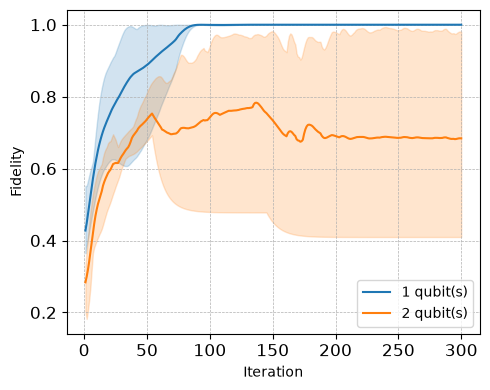

In [16]:
fig2 = plot.plot_fidelity_curves(results)
plot.save_figure(fig2, FIGURE_DIR / "fig2", formats=("png", "eps"))
fig2

## Fig. 3 — ma trận mật độ: quá trình thật $\rho_\mathcal{E}$ vs học được $\rho_k$
Lấy run 1 qubit có loss thấp nhất, trạng thái test đầu tiên.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


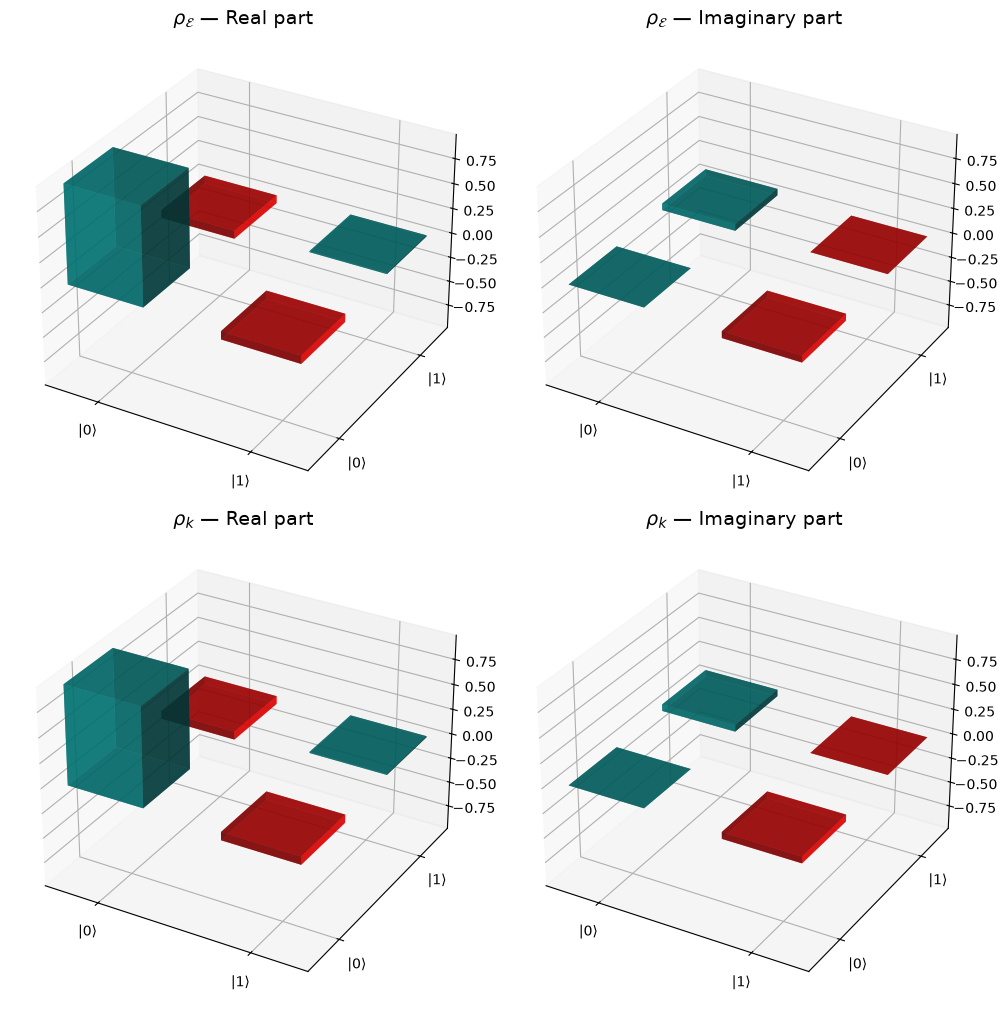

In [17]:
best = min((r for r in results if r.num_qubits == 1), key=lambda r: r.final_loss)
fig3 = plot.plot_density_matrices({
    r"$\rho_\mathcal{E}$": best.evaluation.targets[0],
    r"$\rho_k$": best.evaluation.outputs[0],
})
plot.save_figure(fig3, FIGURE_DIR / "fig3", formats=("png", "eps"))
fig3

## Kiểm tra cuối
Nếu ô này lỗi, xem lại cấu hình (ví dụ tăng `EPOCHS`).

In [18]:
one_qubit = [r for r in results if r.num_qubits == 1]
assert min(r.final_loss for r in one_qubit) < 0.05, "Không run 1-qubit nào hội tụ"
assert all(np.all(np.isfinite(r.loss_history)) for r in results), "Loss có NaN/inf"
assert (FIGURE_DIR / "fig2.png").exists() and (FIGURE_DIR / "fig3.png").exists()
print("OK — full flow chạy thành công")

OK — full flow chạy thành công


---
## Bước tiếp theo
Mở `src/qtomo_skeleton/tomography.py` và điền các TODO bằng code của các khối trên. Khi xong, Phần 1
thu gọn thành:

```python
tomo = KrausTomography(NUM_QUBITS, NUM_RHO, NUM_KRAUS, seed=SEED)                 # [B1]–[B3]
kraus, history = tomo.fit(data_process_fn=data_process_fn, epochs=EPOCHS,
                          optimizer=AdamOptimizer(alpha=LR))                       # [B5]–[B7]
evaluation = Evaluation.from_model(tomo, test_states, target_process_fn)          # [B8]
result = TomographyResult.from_model(tomo, evaluation, seed=SEED)                 # [B9]
```

Kiểm tra: `python -m pytest tests/test_skeleton.py -v`, và `history` phải **trùng** `loss_history` của Phần 1.